# San Ramon 2025-26: rtDD relocation, and where the new sequence lies relative to 2015

SED's double-difference relocator **rtDD** (pyrtdd and scrtdd) was run on the 2025-26 San Ramon sequence on the
Calaveras fault (California) with the settings of the 2015 San Ramon test (notebook 06). This notebook only **loads**
the finished results (step 13, `docs/results/13_sanramon2026_relocation.md`) and shows the key ones; nothing is relocated, and every number in the
text is formatted from the result files.

## Parameters

In [1]:
# ============================== PARAMETERS ==============================
# every setting of this notebook; nothing below changes these values
import time as _time
T_START = _time.time()                                   # the run time is printed at the very end
PROJECT = "/home/msseo/works/74.SeisComP_rtDD_DLpicker"
FIG_DIR = f"{PROJECT}/notebooks/figures"                 # figures as 08_*.png (200 dpi) and 08_*.pdf
FIG_DPI = 200

# --- inputs (all read only) ---
YEARS = ["2015", "2025-26"]
RUN_DIR = {"2015": f"{PROJECT}/runs/sanramon",            # step 11, the 2015 swarm
           "2025-26": f"{PROJECT}/runs/sanramon2026"}     # step 13, the 2025-26 sequence
AN = {y: f"{RUN_DIR[y]}/analysis" for y in YEARS}         # metrics_vs_reference.csv, per_event_vs_reference.csv, ...
ANALYZE_PY = f"{AN['2025-26']}/analyze_sanramon2026.py"   # imported as a module (main() not run): loaders, review_map()
EVENT_CSV = {"2015": f"{PROJECT}/data/sanramon_2015/inputs/rtdd_catalog/event.csv",       # rtDD input = NCSS routine
             "2025-26": f"{PROJECT}/data/sanramon_2026/inputs/rtdd_catalog/event.csv"}
PHASE_CSV = f"{PROJECT}/data/sanramon_2026/inputs/rtdd_catalog/phase.csv"                  # the NCSS picks given to rtDD
TAB = f"{PROJECT}/data/sanramon_2026/reference_tables"
LDEO_CSV = f"{TAB}/ldeo_ddrt_catalog.csv"                # LDEO DD-RT (method and base-catalog columns)
STATIONS_CSV = f"{TAB}/stations_2015_vs_2026.csv"        # stations of both years with their distances
SP_STATS_JSON = f"{TAB}/stats_14.json"                   # S-P residuals of the 2025-26 picks (inputs report)
REPORT = "docs/results/13_sanramon2026_relocation.md"    # the full write-up of step 13

# --- what is compared ---
REF_NAME = {"2015": "LDEO NCAeqDD v202112.1",            # primary reference of each year (names only)
            "2025-26": "LDEO DD-RT NCAeqDDRT.v202201"}
K_NEIGH = 10                       # neighbors of the 'local' metric (asserted equal to the analysis script)
AUTO_FLAGS = ["A", "H"]            # NCSS review flags of events that carry automatic picks only
SECTION_PLANE = "REF_LDEO"         # Figure 1: the section runs along the strike of this catalog's plane fit
MAIN_BODY_ALONG_KM = (-6.0, -1.0)  # Figure 3: the 2025-26 main body (report 13, section 10) lies in this range along
MAIN_BODY_EAST_MIN_KM = 1.0        # the 2015 strike and more than this east of the 2015 plane
NEAR_KM = 1.0                      # a 2025-26 event 'close to a 2015 event' is at most this far from one
ON_PLANE_M = 500.0                 # a 2025-26 event 'on the 2015 plane' is at most this far from it
STATION_RADIUS_KM = 60.0           # radius of the station comparison (the waveform radius of both years)

# --- one color and marker per catalog: identical to notebook 06 (Okabe-Ito); only the labels name the 2025-26
#     references ---
STYLE = {
    "REF_LDEO": dict(label="LDEO DD-RT (primary reference)", short="LDEO DD-RT", color="#000000", marker="o", filled=True, ls="-"),
    "REF_NCEDC": dict(label="NCEDC DD (DD-RT; secondary reference)", short="NCEDC DD", color="#009E73", marker="D", filled=False, ls=":"),
    "NCSS": dict(label="NCSS routine (rtDD start)", short="NCSS routine", color="#808080", marker="o", filled=False, ls="-"),
    "P0": dict(label="pyrtdd P0 (catalog times only)", short="pyrtdd P0", color="#CC79A7", marker="X", filled=False, ls="-"),
    "P1": dict(label="pyrtdd P1 (with cross-correlation)", short="pyrtdd P1", color="#E69F00", marker="^", filled=False, ls="-"),
    "S1": dict(label="scrtdd S1 (with cross-correlation)", short="scrtdd S1", color="#0072B2", marker="s", filled=False, ls="--"),
}
YEAR_COLOR = {"2015": "#56B4E9",   # Okabe-Ito sky blue (no catalog of notebook 06 uses it)
              "2025-26": "#E69F00"}  # = P1's orange: Figure 3 shows the P1 solutions of both years
MS = 6.0                           # marker size (points)
MEW = 1.1                          # marker edge width

# --- Figure 1: the sequence in three catalogs ---
F1_CATALOGS = ["NCSS", "P1", "REF_LDEO"]                 # columns
F1_HALF_M = {"E": 2000, "N": 3000, "along": 3000, "U": 3000}   # half-width of each panel window (m)
F1_IN_PER_KM = 0.55                # the same scale (inches per km) in every panel
F1_SIZE_M1 = 4.0                   # marker area (pt^2) of a magnitude-1 event ...
F1_SIZE_FACTOR = 2.2               # ... multiplied by this per magnitude unit
F1_SIZE_NOMAG = 2.0                # marker area of an event without a magnitude
F1_SIZE_LEGEND = [1, 2, 3, 4]      # magnitudes shown in the size legend
F1_STAR_SIZE = 170.0               # marker area of the mainshock star
F1_CMAP = "viridis"                # color = time

# --- Figure 2: local distance to LDEO DD-RT ---
F2_SOLUTIONS = ["NCSS", "P0", "P1", "S1", "REF_NCEDC"]  # all against LDEO DD-RT
F2_XLIM_M = (5.0, 10000.0)         # logarithmic axis; smaller values are drawn at the left edge

# --- Figure 3: 2025-26 against 2015 (km about the shifted 2015 P1 centroid) ---
F3_EAST_KM = (-3.5, 4.0)           # map view, east
F3_NORTH_KM = (-10.5, 3.0)         # map view, north
F3_ALONG_KM = (-10.5, 3.0)         # fault-parallel section
F3_NORMAL_KM = (-3.5, 4.0)         # fault-normal view
F3_DEPTH_KM = (2.0, 12.0)          # both sections (km below sea level, LDEO frame)
F3_IN_PER_KM = 0.36                # the same scale in every panel
F3_DOT = 5.0                       # marker area of one event (pt^2)
F3_STAR_SIZE = 150.0

In [2]:
# imports, Helvetica, plotting style, small plotting helpers (the last four as in notebook 06)
import os
import sys
import textwrap
import importlib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from matplotlib.ticker import FuncFormatter, MultipleLocator
from scipy.spatial import cKDTree
from IPython.display import display, Markdown
sys.path.insert(0, "/home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/lib")
import nbfont
nbfont.use_helvetica(verbose=True)
import nb08_helpers as hp
importlib.reload(hp)

plt.rcParams.update({"font.size": 9, "axes.titlesize": 9.5, "axes.labelsize": 9, "legend.fontsize": 8,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "figure.dpi": 100,
                     "axes.spines.top": True, "axes.spines.right": True, "axes.spines.left": True,
                     "axes.spines.bottom": True, "mathtext.cal": "Helvetica:italic"})
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option("display.width", 200)
MT = r"$\mathit{M}$"
FIGS = {}


def mk(key, ms=None, filled=None, **over):
    # plot keywords of one catalog (same color and marker in every figure)
    s = STYLE[key]
    f = s["filled"] if filled is None else filled
    kw = dict(ls="none", marker=s["marker"], ms=MS if ms is None else ms, mec=s["color"],
              mfc=s["color"] if f else "white", mew=MEW, color=s["color"])
    kw.update(over)
    return kw


def plain_log(ax, axis="x"):
    # logarithmic axis labeled 0.1, 1, 10, ... instead of powers of ten
    getattr(ax, f"{axis}axis").set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))


def bearing(az):
    # azimuth (deg) -> quadrant bearing such as N7.5°W
    az = az % 360.0
    if az <= 90.0:
        return f"N{az:.1f}°E"
    if az <= 180.0:
        return f"S{180.0 - az:.1f}°E"
    if az <= 270.0:
        return f"S{az - 180.0:.1f}°W"
    return f"N{360.0 - az:.1f}°W"


print("versions: python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__)

font family in use: Helvetica (8 faces registered)
versions: python 3.12.15 | numpy 2.5.4 | pandas 3.0.6 | matplotlib 3.11.2


## What was run, and against what

The next cell reads the result files (listed with their modification times), checks that the numbers used in the
figures agree between files, and writes the introduction from them.

In [3]:
# load every result file (nothing is relocated), check them against each other, and write the introduction
AZ = hp.import_analysis(ANALYZE_PY)
assert AZ.K_NEIGH == K_NEIGH, "K_NEIGH differs from the analysis script"
SOLS = AZ.load_solutions()                     # NCSS start and P0, P1, S0, S1: id, latitude, longitude, depth, E, N, U
REFS, _ = AZ.load_references()                 # LDEO DD-RT and NCEDC DD in the same frame (depths below sea level)
CAT = dict(SOLS)
CAT["REF_LDEO"], CAT["REF_NCEDC"] = REFS["LDEO"], REFS["NCEDC"]
MET, PER, RVR, RT, SUMJ, XST, EV, OPT = ({} for _ in range(8))
used = [ANALYZE_PY, PHASE_CSV, LDEO_CSV, STATIONS_CSV, SP_STATS_JSON]
for y in YEARS:
    f = {k: f"{AN[y]}/{k}" for k in ("metrics_vs_reference.csv", "per_event_vs_reference.csv", "run_vs_run.csv",
                                      "runtime.csv", "summary.json", "xcorr_stats.csv")}
    MET[y] = pd.read_csv(f["metrics_vs_reference.csv"])
    PER[y] = pd.read_csv(f["per_event_vs_reference.csv"])
    RVR[y] = pd.read_csv(f["run_vs_run.csv"])
    RT[y] = pd.read_csv(f["runtime.csv"]).set_index("run")
    SUMJ[y] = hp.read_json(f["summary.json"])
    XST[y] = pd.read_csv(f["xcorr_stats.csv"])
    EV[y] = pd.read_csv(EVENT_CSV[y]).set_index("id")
    OPT[y] = {r: hp.read_json(f"{RUN_DIR[y]}/pyrtdd/{r}/options.json") for r in ("P0", "P1")}
    used += list(f.values()) + [EVENT_CSV[y]] + [f"{RUN_DIR[y]}/pyrtdd/{r}/options.json" for r in ("P0", "P1")]
A26 = AN["2025-26"]
PLANE = pd.read_csv(f"{A26}/plane_fit.csv")
RS = pd.read_csv(f"{A26}/review_split.csv")
ESC = pd.read_csv(f"{A26}/grid_escapes.csv")
DROP = pd.read_csv(f"{A26}/dropped_events.csv")
POS3 = pd.read_csv(f"{A26}/comparison_2015_positions.csv")   # both P1 solutions shifted into LDEO's frame
used += [f"{A26}/{k}" for k in ("plane_fit.csv", "review_split.csv", "grid_escapes.csv", "dropped_events.csv",
                                "comparison_2015_positions.csv")]
C15 = SUMJ["2025-26"]["comparison_2015"]
PH = pd.read_csv(PHASE_CSV)
RV = AZ.review_map()                           # NCSS review flag per event (event_id_map.csv)
LDR = pd.read_csv(LDEO_CSV)
STA = pd.read_csv(STATIONS_CSV)
SPJ = hp.read_json(SP_STATS_JSON)
for p in used:
    print(f"{pd.Timestamp(os.path.getmtime(p), unit='s'):%Y-%m-%d %H:%M}  {os.path.relpath(p, PROJECT)}")


def met(y, sol, ref="LDEO"):
    # one row of metrics_vs_reference.csv
    r = MET[y][(MET[y].solution == sol) & (MET[y].reference == ref)]
    assert len(r) == 1, (y, sol, ref)
    return r.iloc[0]


def per(y, sol, ref="LDEO"):
    # per-event rows of per_event_vs_reference.csv
    return PER[y][(PER[y].solution == sol) & (PER[y].reference == ref)].set_index("id")


def rvr(y, a, b):
    # one row of run_vs_run.csv
    r = RVR[y][(RVR[y].a == a) & (RVR[y].b == b)]
    assert len(r) == 1, (y, a, b)
    return r.iloc[0]


def plane(cat):
    # plane fit of one catalog on the common events (plane_fit.csv)
    r = PLANE[(PLANE.catalog == cat) & PLANE.event_set.str.startswith("common")]
    assert len(r) == 1, cat
    return r.iloc[0]


# the common event set of the analysis: relocated by every run and present in LDEO DD-RT
COMMON = sorted(set.intersection(*[set(SOLS[m].id) for m in AZ.MAIN]) & set(REFS["LDEO"].id))
OT = pd.to_datetime(EV["2025-26"].isotime, format="ISO8601")
MAG = EV["2025-26"].magnitude
MAINSHOCK = int(MAG.idxmax())
AUTO = RV.index[RV.review_version.isin(AUTO_FLAGS)]

# consistency checks between the files (the figures use the per-event files; the text uses the summary files)
checks = [len(COMMON) == SUMJ["2025-26"]["n_common_LDEO"], MAINSHOCK in COMMON]
for y, k in [("2025-26", s) for s in F2_SOLUTIONS] + [("2015", "P1")]:
    p_, m_ = per(y, k), met(y, k)
    checks += [abs(p_.local_dh_med_m.median() - m_.local_h_median_m) < 0.01,
               abs(p_.local_dv_med_m.median() - m_.local_v_median_m) < 0.01]
for k in ("NCSS", "P1"):                       # Figure 1 positions (from the loaders) against the per-event file
    a_ = CAT[k].set_index("id").loc[COMMON, ["E", "N", "U"]]
    r_ = CAT["REF_LDEO"].set_index("id").loc[COMMON, ["E", "N", "U"]]
    d_ = (a_ - a_.mean()) - (r_ - r_.mean())
    p_ = per("2025-26", k).loc[COMMON]
    checks.append(float(np.abs(d_.to_numpy() - p_[["dE_rel_m", "dN_rel_m", "dU_rel_m"]].to_numpy()).max()) < 0.002)
cen = POS3.groupby("set")[["E", "N", "U"]].mean()
sh_ = C15["centroid_shift_2026_minus_2015_P1frame"]
checks.append(np.allclose((cen.loc["P1_2026"] - cen.loc["P1_2015"]).to_numpy(), [sh_["E_m"], sh_["N_m"], sh_["U_m"]], atol=0.1))
checks.append(np.allclose(cen.loc["P1_2015"].to_numpy(), C15["axes"]["origin_ENU_m"], atol=0.1))
assert all(checks), f"{len(checks) - sum(checks)} of {len(checks)} consistency checks failed"
print(f"\n{sum(checks)} of {len(checks)} consistency checks passed")

# the introduction, formatted from the files
y0, y1 = YEARS
nrel = SUMJ[y1]["n_relocated"]
nrel_runs = sorted({nrel[r] for r in ("P0", "P1", "S0", "S1")})
ld = LDR[LDR.is_dd]
mx = {y: OPT[y]["P0"]["ClusteringOptions"]["maxEvStaDist"] for y in YEARS}
nb = {y: met(y, "P1").ref_neighbour_dist_median_m for y in YEARS}
MTYPE = {"W": "Mw", "D": "Md", "L": "ML", "H": "Mh"}
intro = [
    f"**What was run.** rtDD exists as **pyrtdd** (a Python package around its C++ engine libhdd) and **scrtdd** (the "
    f"SeisComP module on the same engine). Both relocated the {len(EV[y1])} events of the {y1} sequence "
    f"({OT.min():%Y-%m-%d} to {OT.max():%Y-%m-%d}; largest {MTYPE.get(RV.loc[MAINSHOCK, 'pref_mag_type'], 'M')} "
    f"{MAG.loc[MAINSHOCK]:.2f} on {OT.loc[MAINSHOCK]:%Y-%m-%d}), starting from the NCSS routine locations with "
    f"{len(PH):,} NCSS picks ({int((PH.type == 'P').sum()):,} P, {int((PH.type == 'S').sum()):,} S). "
    f"{len(AUTO)} of the events were never reviewed by an analyst and carry automatic P picks only. The settings are "
    f"those of the {y0} test, except that stations beyond {mx[y1]:g} km are left out ({y0}: no limit), because the "
    f"travel-time grids end there. **P0** (pyrtdd) and **S0** (scrtdd) use catalog differential times only; **P1** and "
    f"**S1** add waveform cross-correlation. Every run relocated "
    + (f"the same {nrel_runs[0]}" if len(nrel_runs) == 1 else "/".join(map(str, nrel_runs)))
    + f" events in one cluster; {len(COMMON)} of them are also in the primary reference and form the common event set "
    "of every comparison.",
    "",
    f"**References, and why this one is weaker than in {y0}.** The primary reference is the LDEO real-time "
    f"double-difference catalog (**{REF_NAME[y1]}**, method {', '.join(ld.method.unique())}); the NCEDC DD catalog "
    "(also a real-time DD-RT solution) is the secondary reference, and the NCSS routine catalog is the start. In "
    f"{y0} the yardstick was **{REF_NAME[y0]}**, a joint re-inversion of all events with waveform cross-correlation, "
    f"made years later. No such catalog exists for {y1}: DD-RT places each new event on its own, shortly after it "
    f"happens, against older events of LDEO's base catalog ({', '.join(ld.base.unique())}), and never relates the "
    f"{y1} events to each other directly. Its events are also more widely spaced: the median distance from an event "
    f"to its {K_NEIGH} nearest reference neighbors is {nb[y1]:.0f} m, against {nb[y0]:.0f} m in {y0}. Differences "
    "between rtDD and DD-RT smaller than about that spacing cannot be assigned to either side.",
]
display(Markdown("\n".join(intro)))

2026-10-18 06:07  runs/sanramon2026/analysis/analyze_sanramon2026.py
2026-10-18 04:23  data/sanramon_2026/inputs/rtdd_catalog/phase.csv
2026-10-18 03:29  data/sanramon_2026/reference_tables/ldeo_ddrt_catalog.csv
2026-10-18 04:33  data/sanramon_2026/reference_tables/stations_2015_vs_2026.csv
2026-10-18 03:30  data/sanramon_2026/reference_tables/stats_14.json
2026-10-17 13:26  runs/sanramon/analysis/metrics_vs_reference.csv
2026-10-17 13:26  runs/sanramon/analysis/per_event_vs_reference.csv
2026-10-17 13:26  runs/sanramon/analysis/run_vs_run.csv
2026-10-17 13:27  runs/sanramon/analysis/runtime.csv
2026-10-17 13:27  runs/sanramon/analysis/summary.json
2026-10-17 13:27  runs/sanramon/analysis/xcorr_stats.csv
2026-10-17 03:57  data/sanramon_2015/inputs/rtdd_catalog/event.csv
2026-10-17 12:40  runs/sanramon/pyrtdd/P0/options.json
2026-10-17 12:42  runs/sanramon/pyrtdd/P1/options.json
2026-10-18 06:07  runs/sanramon2026/analysis/metrics_vs_reference.csv
2026-10-18 06:07  runs/sanramon2026/ana


18 of 18 consistency checks passed


**What was run.** rtDD exists as **pyrtdd** (a Python package around its C++ engine libhdd) and **scrtdd** (the SeisComP module on the same engine). Both relocated the 927 events of the 2025-26 sequence (2025-10-23 to 2026-09-28; largest Mw 4.18 on 2026-02-02), starting from the NCSS routine locations with 41,870 NCSS picks (37,929 P, 3,941 S). 98 of the events were never reviewed by an analyst and carry automatic P picks only. The settings are those of the 2015 test, except that stations beyond 120 km are left out (2015: no limit), because the travel-time grids end there. **P0** (pyrtdd) and **S0** (scrtdd) use catalog differential times only; **P1** and **S1** add waveform cross-correlation. Every run relocated the same 893 events in one cluster; 842 of them are also in the primary reference and form the common event set of every comparison.

**References, and why this one is weaker than in 2015.** The primary reference is the LDEO real-time double-difference catalog (**LDEO DD-RT NCAeqDDRT.v202201**, method DDRT-3.0); the NCEDC DD catalog (also a real-time DD-RT solution) is the secondary reference, and the NCSS routine catalog is the start. In 2015 the yardstick was **LDEO NCAeqDD v202112.1**, a joint re-inversion of all events with waveform cross-correlation, made years later. No such catalog exists for 2025-26: DD-RT places each new event on its own, shortly after it happens, against older events of LDEO's base catalog (DD202112.1), and never relates the 2025-26 events to each other directly. Its events are also more widely spaced: the median distance from an event to its 10 nearest reference neighbors is 210 m, against 107 m in 2015. Differences between rtDD and DD-RT smaller than about that spacing cannot be assigned to either side.

## Figure 1: the sequence in three catalogs

**What is shown.** The common events in the NCSS routine catalog (rtDD's start), in rtDD with cross-correlation
(pyrtdd P1; scrtdd S1 is the same to a few metres) and in LDEO DD-RT. Each catalog is drawn **relative to its own
centroid** (its average position), so only the shape is compared. Top row: map view. Bottom row: a vertical section
along the strike of LDEO DD-RT's fitted plane (looking at the fault face; up is positive). All panels have the same
scale. Color is the date, marker area grows with magnitude, open circles are events with automatic picks only, and the
star is the mainshock. Events outside a window are counted at its top right.

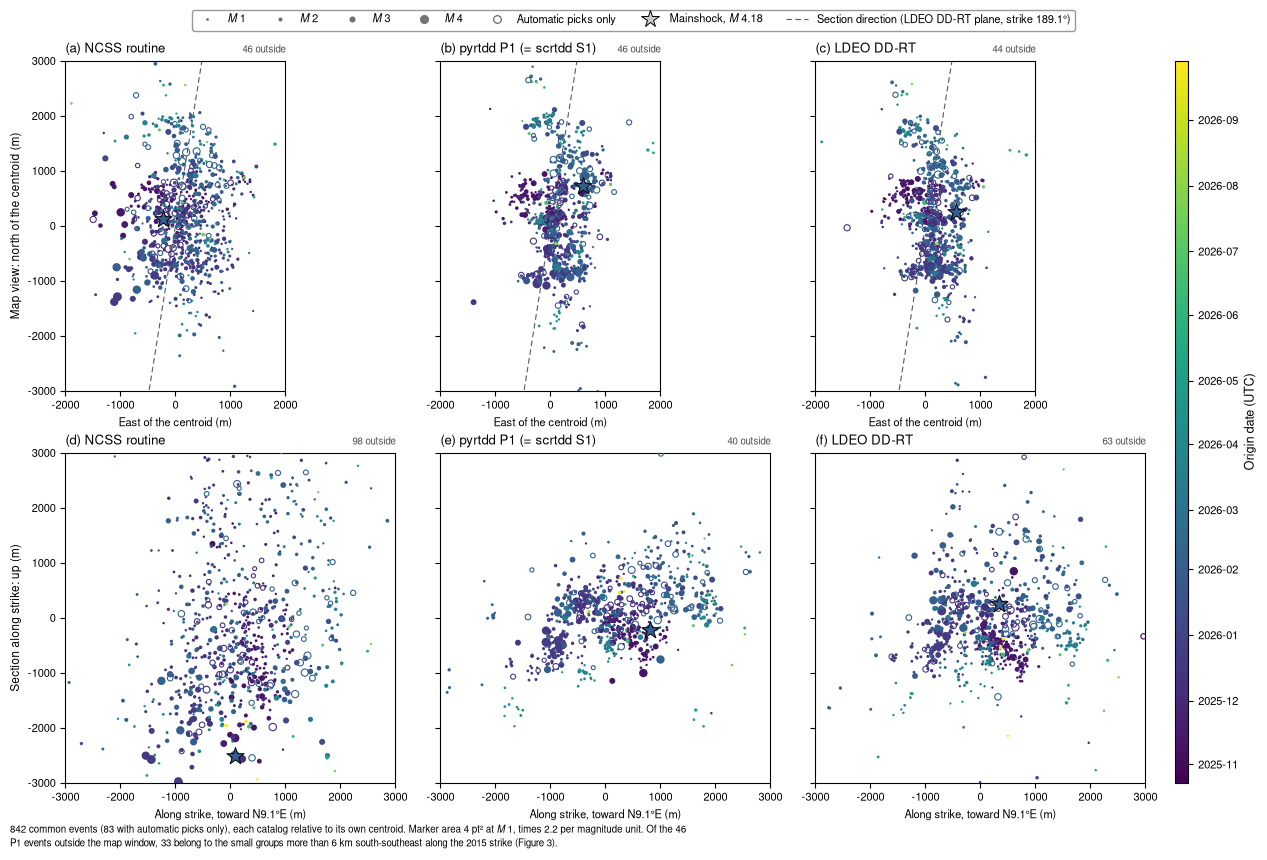

In [4]:
# Figure 1: map view and along-strike section of three catalogs, each relative to its own centroid
SEC_STRIKE = float(plane(SECTION_PLANE).strike)
SEC_DIR = SEC_STRIKE if np.cos(np.radians(SEC_STRIKE)) >= 0 else (SEC_STRIKE + 180.0) % 360.0   # point the section north
F1F = {}
for k in F1_CATALOGS:
    p_ = CAT[k].set_index("id").loc[COMMON, ["E", "N", "U"]].astype(float)
    r_ = p_ - p_.mean()
    al, _ = hp.rotate(r_.E, r_.N, SEC_DIR)
    F1F[k] = pd.DataFrame({"E": r_.E, "N": r_.N, "U": r_.U, "along": al}, index=r_.index)
ROWS1 = [("E", "N", "East of the centroid (m)", "Map view: north of the centroid (m)"),
         ("along", "U", f"Along strike, toward {bearing(SEC_DIR)} (m)", "Section along strike: up (m)")]
DAYS = (OT - OT.min()).dt.total_seconds() / 86400.0
SIZE = (F1_SIZE_M1 * F1_SIZE_FACTOR ** (MAG - 1.0)).fillna(F1_SIZE_NOMAG)
NORM_T = Normalize(0.0, float(DAYS.loc[COMMON].max()))
ORD = np.array(COMMON)[np.argsort(DAYS.loc[COMMON].to_numpy(), kind="stable")]   # earliest drawn first
IS_AUTO = pd.Series(np.isin(ORD, AUTO), index=ORD)
cmap1 = plt.get_cmap(F1_CMAP)
s_ = F1_IN_PER_KM / 1000.0
nc, nr = len(F1_CATALOGS), len(ROWS1)
cw = max(2 * F1_HALF_M[cx] for cx, *_ in ROWS1) * s_
rh = [2 * F1_HALF_M[cy] * s_ for _, cy, *_ in ROWS1]
ml_, mr_, mb_, mt_, gw_, gh_ = 0.85, 1.25, 0.5, 0.3, 0.45, 0.62
W = ml_ + nc * cw + (nc - 1) * gw_ + mr_
H = mb_ + sum(rh) + (nr - 1) * gh_ + mt_
fig = plt.figure(figsize=(W, H))
AX1, NOUT1 = [], {}
letters = iter("abcdefghijklmnopqrstuvwxyz")
y_top = H - mt_
for i, (cx, cy, xl, yl) in enumerate(ROWS1):
    yb = y_top - rh[i]
    for j, k in enumerate(F1_CATALOGS):
        w = 2 * F1_HALF_M[cx] * s_
        ax = fig.add_axes([(ml_ + j * (cw + gw_)) / W, yb / H, w / W, rh[i] / H])
        d = F1F[k].loc[ORD]
        an = ~IS_AUTO.to_numpy()
        ax.scatter(d[cx][an], d[cy][an], c=DAYS.loc[ORD][an], s=SIZE.loc[ORD][an], cmap=cmap1, norm=NORM_T,
                   linewidths=0, zorder=3)
        ax.scatter(d[cx][~an], d[cy][~an], s=SIZE.loc[ORD][~an] * 1.6, facecolors="none",
                   edgecolors=cmap1(NORM_T(DAYS.loc[ORD][~an].to_numpy())), linewidths=0.8, zorder=4)
        m_ = F1F[k].loc[MAINSHOCK]
        ax.scatter([m_[cx]], [m_[cy]], marker="*", s=F1_STAR_SIZE, c=[DAYS.loc[MAINSHOCK]], cmap=cmap1, norm=NORM_T,
                   edgecolors="k", linewidths=0.7, zorder=6)
        if cx == "E":
            t_ = np.array([-3.0, 3.0]) * F1_HALF_M["N"]
            ax.plot(t_ * np.sin(np.radians(SEC_DIR)), t_ * np.cos(np.radians(SEC_DIR)), color="0.35", lw=0.8,
                    ls=(0, (5, 3)), zorder=2)
        ax.set_xlim(-F1_HALF_M[cx], F1_HALF_M[cx])
        ax.set_ylim(-F1_HALF_M[cy], F1_HALF_M[cy])
        ax.set_aspect("equal", adjustable="box")
        ax.xaxis.set_major_locator(MultipleLocator(1000))
        ax.yaxis.set_major_locator(MultipleLocator(1000))
        ax.set_xlabel(xl, fontsize=8)
        if j == 0:
            ax.set_ylabel(yl, fontsize=8.5)
        else:
            ax.tick_params(labelleft=False)
        NOUT1[(k, cx)] = hp.n_outside(F1F[k][cx], F1F[k][cy], ax.get_xlim(), ax.get_ylim())
        ax.set_title(f"({next(letters)}) {STYLE[k]['short']}" + (" (= scrtdd S1)" if k == "P1" else ""), loc="left")
        ax.set_title(f"{NOUT1[(k, cx)]} outside", loc="right", fontsize=7, color="0.3")
        hp.boxed(ax)
        AX1.append(ax)
    y_top = yb - gh_
cax = fig.add_axes([(W - mr_ + 0.3) / W, mb_ / H, 0.13 / W, (H - mb_ - mt_) / H])
cb = fig.colorbar(matplotlib.cm.ScalarMappable(norm=NORM_T, cmap=cmap1), cax=cax)
ticks = hp.month_ticks(OT.min(), OT.loc[COMMON].max())
cb.set_ticks([(t - OT.min()).total_seconds() / 86400.0 for t in ticks])
cb.set_ticklabels([f"{t:%Y-%m}" for t in ticks])
cb.set_label("Origin date (UTC)")
handles = [Line2D([], [], ls="none", marker="o", ms=float(np.sqrt(F1_SIZE_M1 * F1_SIZE_FACTOR ** (m - 1.0))), mfc="0.45",
                  mec="none") for m in F1_SIZE_LEGEND]
labels = [f"{MT} {m:g}" for m in F1_SIZE_LEGEND]
handles += [Line2D([], [], ls="none", marker="o", ms=5.5, mfc="none", mec="0.35", mew=0.8),
            Line2D([], [], ls="none", marker="*", ms=float(np.sqrt(F1_STAR_SIZE)), mfc="0.8", mec="k", mew=0.7),
            Line2D([], [], color="0.35", lw=0.8, ls=(0, (5, 3)))]
labels += ["Automatic picks only", f"Mainshock, {MT} {MAG.loc[MAINSHOCK]:.2f}",
           f"Section direction (LDEO DD-RT plane, strike {SEC_STRIKE:.1f}°)"]
hp.legend_above(fig, AX1 + [cax], handles, labels, ncol=len(handles), fontsize=8)
p3 = POS3[POS3.set == "P1_2026"]
SOUTH = set(p3[p3.along_strike_m < 1000.0 * MAIN_BODY_ALONG_KM[0]].id) & set(COMMON)   # small groups far south (Figure 3)
out_map = F1F["P1"][(F1F["P1"].E.abs() > F1_HALF_M["E"]) | (F1F["P1"].N.abs() > F1_HALF_M["N"])].index
note = (f"{len(COMMON)} common events ({int(IS_AUTO.sum())} with automatic picks only), each catalog relative to its own "
        f"centroid. Marker area {F1_SIZE_M1:g} pt² at {MT} 1, times {F1_SIZE_FACTOR:g} per magnitude unit. Of the "
        f"{len(out_map)} P1 events outside the map window, {len(set(out_map) & SOUTH)} belong to the small groups more than "
        f"{-MAIN_BODY_ALONG_KM[0]:g} km south-southeast along the 2015 strike (Figure 3).")
hp.text_below(fig, AX1[-nc:], textwrap.fill(note, 170), fontsize=7)
FIGS["1"] = hp.save_fig(fig, FIG_DIR, "08_1_sequence_three_catalogs", dpi=FIG_DPI)
plt.show()

In [5]:
# Figure 1: what it says (numbers from the files)
m1 = {k: met(y1, k) for k in ("NCSS", "P0", "P1")}
pl1 = {k: plane(k) for k in F1_CATALOGS}
madU, madNE = {}, {}
for k in F1_CATALOGS:
    mad_ = {c: float((F1F[k][c] - F1F[k][c].median()).abs().median()) for c in ("E", "N", "U")}
    madU[k], madNE[k] = mad_["U"], mad_["N"] / mad_["E"]
rs1 = RS[(RS.solution == "P1") & (RS.reference == "LDEO")].set_index("review_group")
ga = [g for g in rs1.index if g.startswith("A")][0]
gf = [g for g in rs1.index if g.startswith("F")][0]
lines = [
    "- **rtDD collapses the routine catalog's depth scatter to the level of LDEO DD-RT**: the median absolute deviation "
    "of the depths about their median is " + ", ".join(f"{STYLE[k]['short']} {madU[k]:.0f} m" for k in F1_CATALOGS)
    + ". In map view all three are elongated north-south (the north deviation is "
    + ", ".join(f"{madNE[k]:.1f}" for k in F1_CATALOGS) + " times the east deviation).",
    f"- **Shape against LDEO DD-RT** (median over the {len(COMMON)} events, horizontal / vertical): NCSS routine "
    f"{m1['NCSS'].rel_h_median_m:.0f} / {m1['NCSS'].rel_v_median_m:.0f} m, P1 {m1['P1'].rel_h_median_m:.0f} / "
    f"{m1['P1'].rel_v_median_m:.0f} m. With the median offset removed instead of the centroid, P1's vertical number is "
    f"{m1['P1'].rel_v_median_m_mediancentred:.0f} m: a few events with depth errors of several km pull P1's mean depth.",
    f"- **Automatic-only events (open circles) end up only somewhat farther from LDEO DD-RT than analyst events**: P1 local horizontal / "
    f"vertical median {rs1.loc[ga, 'local_h_median_m']:.0f} / {rs1.loc[ga, 'local_v_median_m']:.0f} m for the "
    f"{int(rs1.loc[ga, 'n'])} automatic-only events against {rs1.loc[gf, 'local_h_median_m']:.0f} / "
    f"{rs1.loc[gf, 'local_v_median_m']:.0f} m for the {int(rs1.loc[gf, 'n'])} analyst events (but see the caveats).",
    "- **No single plane describes the sequence in any catalog** (RMS distance from the fitted plane "
    + ", ".join(f"{STYLE[k]['short']} {pl1[k].thickness_rms_m:.0f} m" for k in F1_CATALOGS)
    + "): it has a main body and small separate groups (Figure 3).",
]
display(Markdown("\n".join(lines)))

- **rtDD collapses the routine catalog's depth scatter to the level of LDEO DD-RT**: the median absolute deviation of the depths about their median is NCSS routine 955 m, pyrtdd P1 417 m, LDEO DD-RT 428 m. In map view all three are elongated north-south (the north deviation is 1.8, 2.4, 2.5 times the east deviation).
- **Shape against LDEO DD-RT** (median over the 842 events, horizontal / vertical): NCSS routine 307 / 730 m, P1 145 / 311 m. With the median offset removed instead of the centroid, P1's vertical number is 233 m: a few events with depth errors of several km pull P1's mean depth.
- **Automatic-only events (open circles) end up only somewhat farther from LDEO DD-RT than analyst events**: P1 local horizontal / vertical median 172 / 229 m for the 83 automatic-only events against 137 / 211 m for the 756 analyst events (but see the caveats).
- **No single plane describes the sequence in any catalog** (RMS distance from the fitted plane NCSS routine 784 m, pyrtdd P1 793 m, LDEO DD-RT 725 m): it has a main body and small separate groups (Figure 3).

## Figure 2: how close does rtDD come to LDEO DD-RT?

**What is shown.** For every common event, the *local* difference from LDEO DD-RT: the arrows (vectors) from the
event to its 10 nearest LDEO DD-RT neighbors are drawn in both catalogs, and the median length of the
difference between the two sets of arrows is the event's local difference (horizontal and vertical parts). It asks
whether an event's immediate neighbors lie in the same directions and at the same distances, and ignores where the
sequence sits as a whole. Curves are cumulative distributions (a curve further left = closer to the reference); the
symbol on each curve marks its median. The thin sky-blue curve is the 2015 P1 against its own reference
(LDEO NCAeqDD v202112.1) for comparison; dash-dot lines give each reference's median distance to its 10 nearest
neighbors.

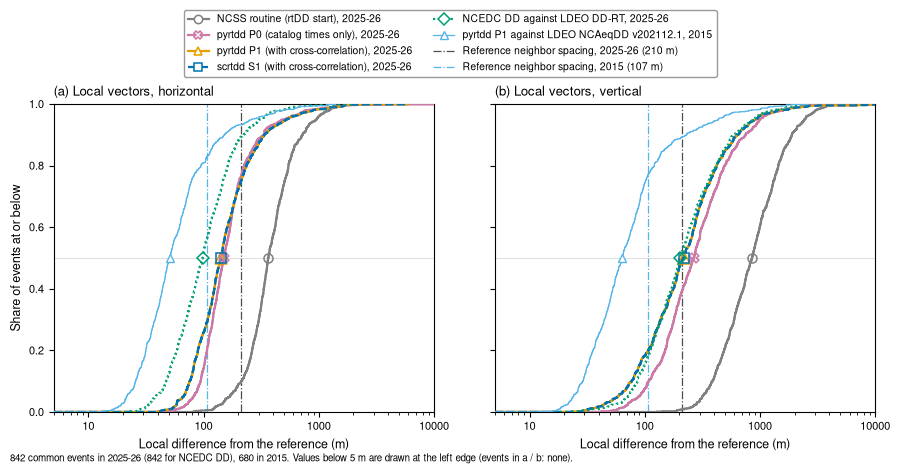

In [6]:
# Figure 2: cumulative distributions of the local difference from LDEO DD-RT (and the 2015 P1 against its LDEO)
PANELS2 = [("local_dh_med_m", "Local vectors, horizontal"), ("local_dv_med_m", "Local vectors, vertical")]
fig, axes = plt.subplots(1, len(PANELS2), figsize=(5.3 * len(PANELS2), 4.0), gridspec_kw=dict(wspace=0.16))
axes = np.atleast_1d(axes)
NLEFT = {}
for i, (ax, (col, tt)) in enumerate(zip(axes, PANELS2)):
    ax.axhline(0.5, color="0.85", lw=0.6, zorder=1)
    for y, c_, lw_ in ((y1, "0.3", 0.9), (y0, YEAR_COLOR[y0], 0.9)):
        ax.axvline(nb[y], color=c_, lw=lw_, ls="-.", zorder=2)
    curves = [(y1, k, STYLE[k]["color"], STYLE[k]["ls"], 1.6) for k in F2_SOLUTIONS] + [(y0, "P1", YEAR_COLOR[y0], "-", 0.9)]
    for y, k, c_, ls_, lw_ in curves:
        d = per(y, k)[col]
        NLEFT[(y, k, col)] = int((d < F2_XLIM_M[0]).sum())
        x, q = hp.ecdf(np.clip(d.to_numpy(), F2_XLIM_M[0], None))
        ax.step(np.r_[F2_XLIM_M[0], x], np.r_[0.0, q], where="post", color=c_, ls=ls_, lw=lw_, zorder=3)
        if y == y1:
            hollow = {} if STYLE[k]["filled"] else {"mfc": "none"}
            ax.plot(float(d.median()), 0.5, **mk(k, ms=9.0 if k == "P1" else 6.5, zorder=4 if k == "P1" else 5, **hollow))
        else:
            ax.plot(float(d.median()), 0.5, ls="none", marker="^", ms=5.5, mfc="white", mec=c_, mew=1.0, zorder=5)
    ax.set_xscale("log")
    ax.set_xlim(F2_XLIM_M)
    ax.set_ylim(0.0, 1.0)
    plain_log(ax, "x")
    ax.set_xlabel("Local difference from the reference (m)")
    if i == 0:
        ax.set_ylabel("Share of events at or below")
    else:
        ax.tick_params(labelleft=False)
    ax.set_title(f"({'abcdefgh'[i]}) {tt}", loc="left")
    hp.boxed(ax)
handles = [Line2D([], [], color=STYLE[k]["color"], ls=STYLE[k]["ls"], lw=1.6, marker=STYLE[k]["marker"], ms=6,
                  mfc=STYLE[k]["color"] if STYLE[k]["filled"] else "white", mec=STYLE[k]["color"], mew=MEW) for k in F2_SOLUTIONS]
labels = [f"{STYLE[k]['label']}, {y1}" if k != "REF_NCEDC" else f"{STYLE[k]['short']} against LDEO DD-RT, {y1}"
          for k in F2_SOLUTIONS]
handles += [Line2D([], [], color=YEAR_COLOR[y0], lw=0.9, marker="^", ms=5.5, mfc="white", mec=YEAR_COLOR[y0], mew=1.0),
            Line2D([], [], color="0.3", lw=0.9, ls="-."), Line2D([], [], color=YEAR_COLOR[y0], lw=0.9, ls="-.")]
labels += [f"pyrtdd P1 against {REF_NAME[y0]}, {y0}",
           f"Reference neighbor spacing, {y1} ({nb[y1]:.0f} m)", f"Reference neighbor spacing, {y0} ({nb[y0]:.0f} m)"]
hp.legend_above(fig, axes, handles, labels, ncol=2, fontsize=7.5)
nl = ", ".join(f"{STYLE[k]['short'] if y == y1 else 'P1 ' + y} {'/'.join(str(NLEFT[(y, k, c)]) for c, _ in PANELS2)}"
               for y, k, *_ in curves if any(NLEFT[(y, k, c)] for c, _ in PANELS2))
note = (f"{len(COMMON)} common events in {y1} ({len(per(y1, 'REF_NCEDC'))} for NCEDC DD), {len(per(y0, 'P1'))} in {y0}. "
        f"Values below {F2_XLIM_M[0]:g} m are drawn at the left edge (events in a / b: {nl if nl else 'none'}).")
hp.text_below(fig, list(axes), textwrap.fill(note, 150), fontsize=7)
FIGS["2"] = hp.save_fig(fig, FIG_DIR, "08_2_local_distance_to_ldeo", dpi=FIG_DPI)
plt.show()

In [7]:
# Figure 2: what it says
m2 = {(y, k): met(y, k) for y in YEARS for k in ("NCSS", "P0", "P1")}
m2[(y1, "S1")], m2[(y1, "REF_NCEDC")] = met(y1, "S1"), met(y1, "REF_NCEDC")


def gain(y, comp):
    # relative drop of the local median from P0 to P1 (%)
    a, b = m2[(y, "P0")][f"local_{comp}_median_m"], m2[(y, "P1")][f"local_{comp}_median_m"]
    return 100.0 * (a - b) / a


def hv(y, k):
    return f"{m2[(y, k)].local_h_median_m:.0f} / {m2[(y, k)].local_v_median_m:.0f} m"


lines = [
    f"- **rtDD improves the routine catalog about {m2[(y1, 'P1')].improvement_rel_3d:.1f}×** (relative 3-D median, NCSS "
    f"start / solution; P0 {m2[(y1, 'P0')].improvement_rel_3d:.1f}×, P1 {m2[(y1, 'P1')].improvement_rel_3d:.1f}×). "
    f"Local horizontal / vertical medians: NCSS {hv(y1, 'NCSS')}, P0 {hv(y1, 'P0')}, P1 {hv(y1, 'P1')}; "
    f"{100 * m2[(y1, 'P1')].frac_events_closer_than_NCSS_local:.0f} % of the events end locally closer to LDEO DD-RT "
    "than they started.",
    f"- **Cross-correlation adds little this time.** From P0 to P1 the local medians fall by {gain(y1, 'h'):.0f} % "
    f"horizontally and {gain(y1, 'v'):.0f} % vertically. In {y0} the same step cut them by {gain(y0, 'h'):.0f} % and "
    f"{gain(y0, 'v'):.0f} % ({hv(y0, 'P0')} → {hv(y0, 'P1')}). P1 now sits at {m2[(y1, 'P1')].local_h_median_m / nb[y1]:.2f} "
    f"of the reference's neighbor spacing horizontally ({y0}: {m2[(y0, 'P1')].local_h_median_m / nb[y0]:.2f}), so the "
    "yardstick itself may limit what can be seen.",
    f"- **scrtdd S1 lies on top of pyrtdd P1** (local {hv(y1, 'S1')}). NCEDC DD agrees with LDEO DD-RT better "
    f"({hv(y1, 'REF_NCEDC')}), but both are real-time DD-RT solutions on the same base catalog and picks, so this "
    "agreement is not an independent check.",
]
display(Markdown("\n".join(lines)))

- **rtDD improves the routine catalog about 2.4×** (relative 3-D median, NCSS start / solution; P0 2.4×, P1 2.4×). Local horizontal / vertical medians: NCSS 365 / 853 m, P0 149 / 265 m, P1 142 / 217 m; 94 % of the events end locally closer to LDEO DD-RT than they started.
- **Cross-correlation adds little this time.** From P0 to P1 the local medians fall by 5 % horizontally and 18 % vertically. In 2015 the same step cut them by 63 % and 57 % (137 / 147 m → 51 / 63 m). P1 now sits at 0.67 of the reference's neighbor spacing horizontally (2015: 0.47), so the yardstick itself may limit what can be seen.
- **scrtdd S1 lies on top of pyrtdd P1** (local 141 / 217 m). NCEDC DD agrees with LDEO DD-RT better (98 / 204 m), but both are real-time DD-RT solutions on the same base catalog and picks, so this agreement is not an independent check.

## Figure 3: the 2025-26 sequence and the 2015 swarm in one frame

**Method in one sentence.** Each year's P1 solution keeps its own relative geometry and is shifted by its own mean
offset from its LDEO reference on its common events, which puts both into LDEO's geoid frame (DD-RT is tied to the
same base catalog as the 2015 reference). **What is shown** (km about the centroid of the shifted 2015 P1, the same
scale in every panel): (a) map view with the strike line of the 2015 swarm's fitted plane through its centroid,
and the same line moved east by the median offset of the 2025-26 main body; (b) a section along the 2015 strike
(looking at the fault face from the east-northeast); (c) a fault-normal view (looking along the 2015 strike toward the
north-northwest; distance from the 2015 plane). Large diamonds are the five 2015 events that lie on the 2025-26 strand;
stars are the largest event of each year.

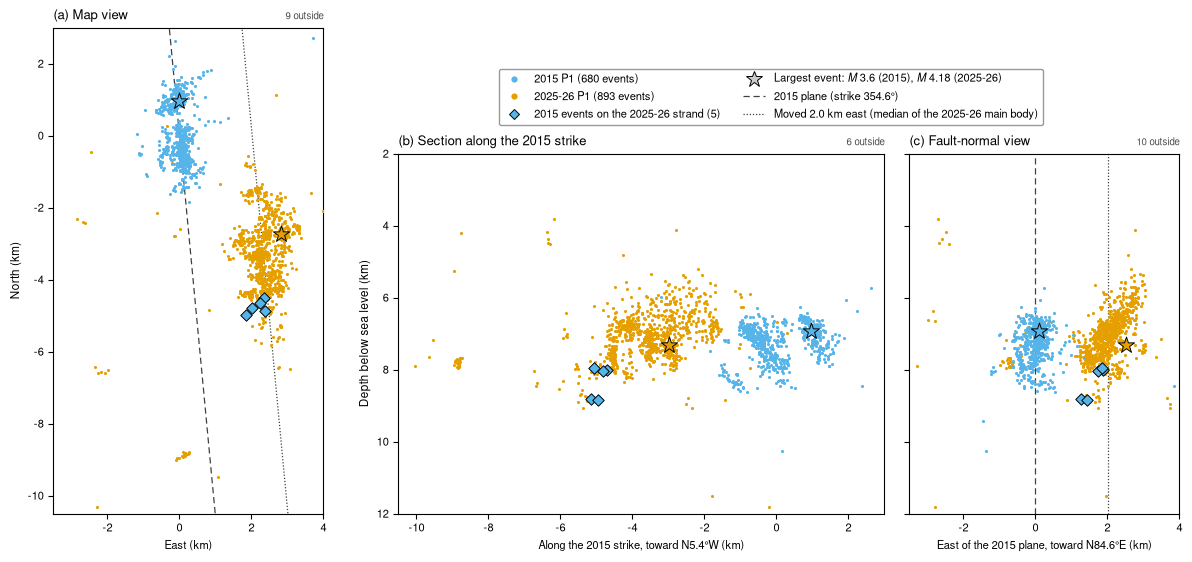

In [8]:
# Figure 3: map view, fault-parallel section and fault-normal view of both P1 solutions in LDEO's frame
O = np.array(C15["axes"]["origin_ENU_m"])        # centroid of the shifted 2015 P1
STRIKE15 = float(C15["plane_2015_P1_shifted"]["strike"])
NORMAL_AZ = float(C15["plane_2015_P1_shifted"]["dip_direction"])
G = {}
for y, s_name in ((y0, "P1_2015"), (y1, "P1_2026")):
    g = POS3[POS3.set == s_name].set_index("id")
    G[y] = pd.DataFrame({"east": (g.E - O[0]) / 1000.0, "north": (g.N - O[1]) / 1000.0, "depth": -g.U / 1000.0,
                         "along": g.along_strike_m / 1000.0, "normal": g.normal_m / 1000.0})
MB = G[y1][G[y1].along.between(*MAIN_BODY_ALONG_KM, inclusive="left") & (G[y1].normal > MAIN_BODY_EAST_MIN_KM)]
SE15 = G[y0][G[y0].along.between(*MAIN_BODY_ALONG_KM, inclusive="left") & (G[y0].normal > MAIN_BODY_EAST_MIN_KM)]
OFF_MB = float(MB.normal.median())
BIG = {y0: int(EV[y0].magnitude.idxmax()), y1: MAINSHOCK}
assert all(BIG[y] in G[y].index for y in YEARS)
PANELS3 = [("east", "north", F3_EAST_KM, F3_NORTH_KM, "Map view", "East (km)", "North (km)"),
           ("along", "depth", F3_ALONG_KM, F3_DEPTH_KM, "Section along the 2015 strike",
            f"Along the 2015 strike, toward {bearing(STRIKE15)} (km)", "Depth below sea level (km)"),
           ("normal", "depth", F3_NORMAL_KM, F3_DEPTH_KM, "Fault-normal view",
            f"East of the 2015 plane, toward {bearing(NORMAL_AZ)} (km)", "Depth below sea level (km)")]
wid = [(p[2][1] - p[2][0]) * F3_IN_PER_KM for p in PANELS3]
hgt = [(p[3][1] - p[3][0]) * F3_IN_PER_KM for p in PANELS3]
ml_, mr_, mb_, mt_, gw_ = 0.6, 0.15, 0.55, 0.3, [0.75, 0.25]
W = ml_ + sum(wid) + sum(gw_[:len(PANELS3) - 1]) + mr_
H = mb_ + max(hgt) + mt_
fig = plt.figure(figsize=(W, H))
AX3, NOUT3 = [], {}
x_ = ml_
for i, (cx, cy, xr, yr, tt, xl, yl) in enumerate(PANELS3):
    ax = fig.add_axes([x_ / W, mb_ / H, wid[i] / W, hgt[i] / H])        # bottom-aligned
    x_ += wid[i] + (gw_[i] if i < len(gw_) else 0.0)
    for y in (y1, y0):
        ax.scatter(G[y][cx], G[y][cy], s=F3_DOT, color=YEAR_COLOR[y], linewidths=0, zorder=3 if y == y1 else 4)
    ax.scatter(SE15[cx], SE15[cy], s=34, marker="D", color=YEAR_COLOR[y0], edgecolors="k", linewidths=0.7, zorder=6)
    for y in YEARS:
        ax.scatter([G[y].loc[BIG[y], cx]], [G[y].loc[BIG[y], cy]], marker="*", s=F3_STAR_SIZE, color=YEAR_COLOR[y],
                   edgecolors="k", linewidths=0.7, zorder=7)
    if cx == "east":
        t_ = np.array([-30.0, 30.0])
        se, sn = np.sin(np.radians(STRIKE15)), np.cos(np.radians(STRIKE15))
        ne, nn = np.sin(np.radians(STRIKE15 + 90.0)), np.cos(np.radians(STRIKE15 + 90.0))
        ax.plot(t_ * se, t_ * sn, color="0.25", lw=0.9, ls=(0, (5, 3)), zorder=2)
        ax.plot(t_ * se + OFF_MB * ne, t_ * sn + OFF_MB * nn, color="0.25", lw=0.9, ls=(0, (1, 1.5)), zorder=2)
    if cx == "normal":
        ax.axvline(0.0, color="0.25", lw=0.9, ls=(0, (5, 3)), zorder=2)
        ax.axvline(OFF_MB, color="0.25", lw=0.9, ls=(0, (1, 1.5)), zorder=2)
    ax.set_xlim(xr)
    ax.set_ylim(yr[::-1] if cy == "depth" else yr)
    ax.set_aspect("equal", adjustable="box")
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.yaxis.set_major_locator(MultipleLocator(2))
    ax.set_xlabel(xl, fontsize=8)
    if i == 2:
        ax.tick_params(labelleft=False)
    else:
        ax.set_ylabel(yl, fontsize=8.5)
    NOUT3[cx] = sum(hp.n_outside(G[y][cx], G[y][cy], xr, yr) for y in YEARS)
    ax.set_title(f"({'abc'[i]}) {tt}", loc="left")
    ax.set_title(f"{NOUT3[cx]} outside", loc="right", fontsize=7, color="0.3")
    hp.boxed(ax)
    AX3.append(ax)
handles = [Line2D([], [], ls="none", marker="o", ms=4.5, mfc=YEAR_COLOR[y], mec="none") for y in YEARS]
labels = [f"{y} P1 ({len(G[y])} events)" for y in YEARS]
handles += [Line2D([], [], ls="none", marker="D", ms=5.5, mfc=YEAR_COLOR[y0], mec="k", mew=0.7),
            Line2D([], [], ls="none", marker="*", ms=12, mfc="0.8", mec="k", mew=0.7),
            Line2D([], [], color="0.25", lw=0.9, ls=(0, (5, 3))), Line2D([], [], color="0.25", lw=0.9, ls=(0, (1, 1.5)))]
labels += [f"{y0} events on the {y1} strand ({len(SE15)})",
           f"Largest event: {MT} {EV[y0].magnitude.loc[BIG[y0]]:.1f} ({y0}), {MT} {MAG.loc[MAINSHOCK]:.2f} ({y1})",
           f"{y0} plane (strike {STRIKE15:.1f}°)", f"Moved {OFF_MB:.1f} km east (median of the {y1} main body)"]
# the sections are shorter than the map: their legend goes above them, beside the top of the map
hp.legend_above(fig, AX3[1:], handles, labels, ncol=2, fontsize=8)
FIGS["3"] = hp.save_fig(fig, FIG_DIR, "08_3_2026_vs_2015", dpi=FIG_DPI)
plt.show()

In [9]:
# Figure 3: what it says (numbers from the files; the main-body plane from the analysis script's own plane_fit())
shL = C15["centroid_shift_2026_minus_2015_LDEO_benchmark"]
shN = C15["centroid_shift_2026_minus_2015_P1frame_NCEDCoffsets"]
pos26 = POS3[POS3.set == "P1_2026"].set_index("id")
pf_mb = AZ.plane_fit(pos26.loc[MB.index, ["E", "N", "U"]].to_numpy())
l26 = POS3[POS3.set == "LDEO_2026"]
l_mb = l26[l26.along_strike_m.between(*(1000.0 * np.array(MAIN_BODY_ALONG_KM)), inclusive="left")
           & (l26.normal_m > 1000.0 * MAIN_BODY_EAST_MIN_KM)]
pf_mbL = AZ.plane_fit(l_mb[["E", "N", "U"]].to_numpy())
dstr = [hp.strike_difference(p["strike"], STRIKE15) for p in (pf_mb, pf_mbL)]
tree = cKDTree(POS3[POS3.set == "P1_2015"][["E", "N", "U"]].to_numpy())
dist, idx = tree.query(pos26[["E", "N", "U"]].to_numpy())
ids15 = POS3[POS3.set == "P1_2015"].id.to_numpy()
near = dist <= 1000.0 * NEAR_KM
n_by_se = int(np.isin(ids15[idx[near]], SE15.index).sum())
a15 = C15["along_strike_2015_P1_p05_p95_m"]
a26 = C15["along_strike_2026_P1_p05_p95_m"]
q = MB.normal.quantile([0.1, 0.9])
amb = MB.along.quantile([0.05, 0.95])            # main body along the 2015 strike (km; negative = SSE)
FIG3 = dict(n_east=int((G[y1].normal > MAIN_BODY_EAST_MIN_KM).sum()), n_on=int((G[y1].normal.abs() <= ON_PLANE_M / 1000.0).sum()),
            n_mb=len(MB), off=OFF_MB, near=int(near.sum()), n_by_se=n_by_se)
lines = [
    f"- **The {y1} sequence lies south-southeast of the {y0} swarm**: its centroid is {sh_['h_km']:.2f} km away toward "
    f"{sh_['azimuth_deg']:.0f}° and {sh_['U_m']:.0f} m shallower (with NCEDC DD-based offsets: {shN['h_km']:.2f} km toward "
    f"{shN['azimuth_deg']:.0f}°; the two LDEO catalogs alone: {shL['h_km']:.2f} km toward {shL['azimuth_deg']:.0f}°). Along "
    f"the {y0} strike its main body lies {-amb.iloc[1]:.1f}–{-amb.iloc[0]:.1f} km SSE of the {y0} centroid (5–95 %; all "
    f"events {-a26[1] / 1000:.1f}–{-a26[0] / 1000:.1f} km), beyond the {y0} swarm itself ({a15[0] / 1000:.1f} to "
    f"+{a15[1] / 1000:.1f} km).",
    f"- **It lies on a parallel strand about {OFF_MB:.1f} km east of the {y0} plane.** {FIG3['n_east']} of its {len(G[y1])} "
    f"events are more than {MAIN_BODY_EAST_MIN_KM:g} km east of that plane and only {FIG3['n_on']} lie within "
    f"{ON_PLANE_M:.0f} m of it. The main body ({len(MB)} events, {MAIN_BODY_ALONG_KM[0]:g} to {MAIN_BODY_ALONG_KM[1]:g} km "
    f"along strike) lies {q.iloc[0]:.1f}–{q.iloc[1]:.1f} km east (10–90 %); its own plane strikes {pf_mb['strike']:.1f}° "
    f"and dips {pf_mb['dip']:.1f}° in P1 ({pf_mbL['strike']:.1f}° / {pf_mbL['dip']:.1f}° in LDEO DD-RT), within "
    f"{min(dstr):.1f}–{max(dstr):.1f}° of the {y0} strike ({STRIKE15:.1f}°).",
    f"- **The {y0} strand was not reactivated.** The only {y0} events on the new strand are the {len(SE15)} shown as "
    f"diamonds; they are the nearest {y0} event for {n_by_se} of the {FIG3['near']} {y1} events that lie within "
    f"{NEAR_KM:g} km of any {y0} event. Median depths are the same: {G[y1].depth.median():.1f} km ({y1}) and "
    f"{G[y0].depth.median():.1f} km ({y0}).",
    f"- {int((G[y1].along < MAIN_BODY_ALONG_KM[0]).sum())} of the {y1} events lie more than {-MAIN_BODY_ALONG_KM[0]:g} km "
    f"SSE along strike, beyond the main body (panel b; LDEO DD-RT: "
    f"{int((l26.along_strike_m < 1000.0 * MAIN_BODY_ALONG_KM[0]).sum())} of its {len(l26)} events).",
]
display(Markdown("\n".join(lines)))

- **The 2025-26 sequence lies south-southeast of the 2015 swarm**: its centroid is 4.10 km away toward 147° and 178 m shallower (with NCEDC DD-based offsets: 4.13 km toward 145°; the two LDEO catalogs alone: 4.10 km toward 148°). Along the 2015 strike its main body lies 1.8–4.7 km SSE of the 2015 centroid (5–95 %; all events 1.8–5.6 km), beyond the 2015 swarm itself (-1.2 to +1.4 km).
- **It lies on a parallel strand about 2.0 km east of the 2015 plane.** 846 of its 893 events are more than 1 km east of that plane and only 8 lie within 500 m of it. The main body (835 events, -6 to -1 km along strike) lies 1.5–2.6 km east (10–90 %); its own plane strikes 179.1° and dips 85.5° in P1 (173.1° / 85.3° in LDEO DD-RT), within 1.5–4.5° of the 2015 strike (354.6°).
- **The 2015 strand was not reactivated.** The only 2015 events on the new strand are the 5 shown as diamonds; they are the nearest 2015 event for 156 of the 161 2025-26 events that lie within 1 km of any 2015 event. Median depths are the same: 7.1 km (2025-26) and 7.2 km (2015).
- 36 of the 2025-26 events lie more than 6 km SSE along strike, beyond the main body (panel b; LDEO DD-RT: 34 of its 864 events).

## Summary

Key numbers of both years side by side, all from the result files. "Relative" = each event's position minus its
catalog's centroid, compared with the same in the reference; "local" = the neighbor-vector difference of Figure 2;
H / V = horizontal / vertical medians over the common events; improvement = the NCSS start's median 3-D relative
difference divided by the solution's.

In [10]:
# summary table: 2015 against 2025-26
def hvr(y, k, kind="rel"):
    m = met(y, k)
    return f"{m[f'{kind}_h_median_m']:.0f} / {m[f'{kind}_v_median_m']:.0f}"


def n_in(y):
    return len(EV[y])


def lag_pct(y):
    x = SUMJ[y]["xcorr_pyrtdd_vs_scrtdd"]["P1_vs_S1"]
    return 100.0 * x["lag_identical"] / x["both_valid"]


def fmt_km_m(v):
    return f"{v / 1000:.1f} km" if v >= 1000 else f"{v:.0f} m"


rows = [
    ("Events in the input / relocated by every run", {y: f"{n_in(y)} / {SUMJ[y]['n_relocated']['P1']}" for y in YEARS}),
    ("Primary reference", {y: REF_NAME[y] for y in YEARS}),
    ("Common events with the reference", {y: f"{met(y, 'P1').n:.0f}" for y in YEARS}),
    ("Reference neighbor spacing (m)", {y: f"{nb[y]:.0f}" for y in YEARS}),
    ("NCSS start vs reference: relative H / V (m)", {y: hvr(y, "NCSS") for y in YEARS}),
    ("NCSS start vs reference: local H / V (m)", {y: hvr(y, "NCSS", "local") for y in YEARS}),
    ("P0 vs reference: relative H / V (m)", {y: hvr(y, "P0") for y in YEARS}),
    ("P0 vs reference: local H / V (m)", {y: hvr(y, "P0", "local") for y in YEARS}),
    ("P1 vs reference: relative H / V (m); vertical with the median offset removed",
     {y: f"{hvr(y, 'P1')}; {met(y, 'P1').rel_v_median_m_mediancentred:.0f}" for y in YEARS}),
    ("P1 vs reference: local H / V (m)", {y: hvr(y, "P1", "local") for y in YEARS}),
    ("Improvement over the start, relative 3-D: P0 / P1",
     {y: f"{met(y, 'P0').improvement_rel_3d:.1f} / {met(y, 'P1').improvement_rel_3d:.1f}" for y in YEARS}),
    ("Improvement over the start, local H / V: P1",
     {y: f"{met(y, 'P1').improvement_local_h:.1f} / {met(y, 'P1').improvement_local_v:.1f}" for y in YEARS}),
    ("Events closer than the start, P1 (relative 3-D / local)",
     {y: f"{100 * met(y, 'P1').frac_events_closer_than_NCSS_rel3d:.0f} % / {100 * met(y, 'P1').frac_events_closer_than_NCSS_local:.0f} %"
      for y in YEARS}),
    ("scrtdd S1 vs pyrtdd P1: median / largest 3-D difference; identical lags",
     {y: f"{rvr(y, 'P1', 'S1').abs3d_median_m:.1f} m / {fmt_km_m(rvr(y, 'P1', 'S1').abs3d_max_m)}; {lag_pct(y):.1f} %" for y in YEARS}),
    ("P1 centroid vs reference, E / N / U (m; U < 0 = too deep)",
     {y: f"{met(y, 'P1').centroid_shift_E_m:+.0f} / {met(y, 'P1').centroid_shift_N_m:+.0f} / {met(y, 'P1').centroid_shift_U_m:+.0f}"
      for y in YEARS}),
    ("Wall time P0 / S0 / P1 / S1", {y: " / ".join(hp.fmt_duration(RT[y].loc[r, "wall_s"]) for r in ("P0", "S0", "P1", "S1"))
                                     for y in YEARS}),
    ("Peak memory P0 / S0 / P1 / S1 (MB)", {y: " / ".join(f"{RT[y].loc[r, 'peak_rss_mb']:,.0f}" for r in ("P0", "S0", "P1", "S1"))
                                            for y in YEARS}),
]
SUMMARY = pd.DataFrame([{"Quantity": q, **v} for q, v in rows])
display(Markdown(hp.md_table(SUMMARY)))

| Quantity | 2015 | 2025-26 |
|---|---|---|
| Events in the input / relocated by every run | 685 / 680 | 927 / 893 |
| Primary reference | LDEO NCAeqDD v202112.1 | LDEO DD-RT NCAeqDDRT.v202201 |
| Common events with the reference | 680 | 842 |
| Reference neighbor spacing (m) | 107 | 210 |
| NCSS start vs reference: relative H / V (m) | 229 / 394 | 307 / 730 |
| NCSS start vs reference: local H / V (m) | 292 / 506 | 365 / 853 |
| P0 vs reference: relative H / V (m) | 142 / 134 | 167 / 274 |
| P0 vs reference: local H / V (m) | 137 / 147 | 149 / 265 |
| P1 vs reference: relative H / V (m); vertical with the median offset removed | 97 / 105; 107 | 145 / 311; 233 |
| P1 vs reference: local H / V (m) | 51 / 63 | 142 / 217 |
| Improvement over the start, relative 3-D: P0 / P1 | 2.1 / 2.9 | 2.4 / 2.4 |
| Improvement over the start, local H / V: P1 | 5.8 / 8.0 | 2.6 / 3.9 |
| Events closer than the start, P1 (relative 3-D / local) | 89 % / 98 % | 77 % / 94 % |
| scrtdd S1 vs pyrtdd P1: median / largest 3-D difference; identical lags | 1.1 m / 6.3 km; 97.9 % | 1.0 m / 25 m; 97.8 % |
| P1 centroid vs reference, E / N / U (m; U < 0 = too deep) | -826 / -204 / -2254 | -1366 / -495 / -2396 |
| Wall time P0 / S0 / P1 / S1 | 55 s / 54 s / 27.9 min / 19.4 min | 91 s / 114 s / 38.4 min / 29.0 min |
| Peak memory P0 / S0 / P1 / S1 (MB) | 437 / 356 / 1,008 / 756 | 626 / 532 / 1,536 / 1,118 |

In [11]:
# take-home messages and caveats (numbers from the files)
mP0, mP1 = met(y1, "P0"), met(y1, "P1")
r11 = rvr(y1, "P1", "S1")
esc = ESC[ESC.iterations_with_all_ttt_failed > 0]
n_esc = {r: esc[esc.run == r].id.nunique() for r in ("P0", "S0", "P1", "S1")}
esc_flags = sorted(esc.review.unique())
drop = DROP[DROP.run == "P1"]
n_drop_auto_I = int(drop.review.isin(AUTO_FLAGS + ["I"]).sum())
STA["net_sta"] = STA.nsl.str.rsplit(".", n=1).str[0]
near_sta = {y: set(STA[STA[f"dist_{'2015' if y == y0 else '2026'}_km"] <= STATION_RADIUS_KM].net_sta) for y in YEARS}
n_common_sta = len(near_sta[y0] & near_sta[y1])
xs = XST[y1][XST[y1].run == "P1"].set_index("phase")
s_share = 100.0 * xs.loc["S", "entries"] / xs.loc["all", "entries"]
sp_res = SPJ["median_sp_residual_s"]["Vp/Vs 1.73"]
take = [
    f"- **rtDD works on the 2025-26 sequence as it did in 2015.** All four runs relocated "
    f"{SUMJ[y1]['n_relocated']['P1']} of {n_in(y1)} events and bring them about {mP1.improvement_rel_3d:.1f}× closer to "
    f"LDEO DD-RT's structure than the routine catalog (P0 {mP0.improvement_rel_3d:.1f}×; {y0}: "
    f"{met(y0, 'P0').improvement_rel_3d:.1f}× and {met(y0, 'P1').improvement_rel_3d:.1f}×).",
    f"- **Cross-correlation adds little this time** (local medians −{gain(y1, 'h'):.0f} % / −{gain(y1, 'v'):.0f} % from P0 "
    f"to P1, against −{gain(y0, 'h'):.0f} % / −{gain(y0, 'v'):.0f} % in {y0}). The data cannot say whether the weaker "
    "reference, the wider sequence, the changed station network or the lower correlation quality is the cause.",
    f"- **pyrtdd and scrtdd give the same answer**: S1 is a median {r11.abs3d_median_m:.1f} m from P1 (largest "
    f"{r11.abs3d_max_m:.0f} m), and {lag_pct(y1):.1f} % of the measured lags are identical.",
    f"- **The new sequence activated a parallel strand, not the {y0} one**: about {OFF_MB:.1f} km east of the {y0} plane, "
    f"its main body {-amb.iloc[1]:.0f}–{-amb.iloc[0]:.0f} km SSE of the {y0} centroid along strike (5–95 %), at the same "
    f"depth (medians {G[y1].depth.median():.1f} and {G[y0].depth.median():.1f} km).",
    f"- **Use the relative geometry only.** The default solver puts the whole cluster {-mP1.centroid_shift_U_m / 1000:.1f} km "
    f"too deep and {-mP1.centroid_shift_E_m / 1000:.1f} km too far west of LDEO DD-RT ({y0}: "
    f"{-met(y0, 'P1').centroid_shift_U_m / 1000:.1f} km too deep).",
]
cav = [
    f"- **Weaker reference.** LDEO DD-RT is a real-time solution, not a joint cross-correlation re-analysis, and its "
    f"neighbor spacing is {nb[y1]:.0f} m ({y0}: {nb[y0]:.0f} m). \"Closer to LDEO DD-RT\" means closer to the real-time DD "
    "solution, not closer to the truth.",
    f"- **Automatic-only events and grid escapes.** {len(AUTO)} events were never reviewed (automatic P picks only, no S). "
    f"Together with the 'I' events they make up {n_drop_auto_I} of the {drop.id.nunique()} dropped events, and every "
    f"event that left the travel-time grid during the iterations ({n_esc['P0']} in P0/S0, {n_esc['P1']} in P1/S1) has "
    f"review flag {', '.join(esc_flags)}.",
    f"- **Station network changes.** Only {n_common_sta} of the stations within {STATION_RADIUS_KM:g} km are common to both "
    f"years ({len(near_sta[y0])} in {y0}, {len(near_sta[y1])} in {y1}; the dense near-field sites of {y0} are mostly gone), "
    "so the two years do not see their sequences through the same stations.",
    f"- **Near-station S delay.** Near-station S picks arrive late: with Vp/Vs 1.73 the median S−P residual is "
    f"+{sp_res:.2f} s. It cancels in double differences but not in the absolute equations, and S makes up only "
    f"{s_share:.1f} % of the phase pairs, which limits depth resolution.",
    f"- **Absolute depth is {-mP1.centroid_shift_U_m / 1000:.1f} km too deep** (P1 against LDEO DD-RT); Figure 3 therefore "
    "uses LDEO's frame, not rtDD's absolute positions.",
]
display(Markdown("**Take-home messages**\n\n" + "\n".join(take) + "\n\n**Caveats**\n\n" + "\n".join(cav)
                 + f"\n\nFull write-up: `{REPORT}`."))
print("figures written:")
for k_, (png, pdf) in FIGS.items():
    print(f"  Figure {k_}: {png}  |  {pdf}")

**Take-home messages**

- **rtDD works on the 2025-26 sequence as it did in 2015.** All four runs relocated 893 of 927 events and bring them about 2.4× closer to LDEO DD-RT's structure than the routine catalog (P0 2.4×; 2015: 2.1× and 2.9×).
- **Cross-correlation adds little this time** (local medians −5 % / −18 % from P0 to P1, against −63 % / −57 % in 2015). The data cannot say whether the weaker reference, the wider sequence, the changed station network or the lower correlation quality is the cause.
- **pyrtdd and scrtdd give the same answer**: S1 is a median 1.0 m from P1 (largest 25 m), and 97.8 % of the measured lags are identical.
- **The new sequence activated a parallel strand, not the 2015 one**: about 2.0 km east of the 2015 plane, its main body 2–5 km SSE of the 2015 centroid along strike (5–95 %), at the same depth (medians 7.1 and 7.2 km).
- **Use the relative geometry only.** The default solver puts the whole cluster 2.4 km too deep and 1.4 km too far west of LDEO DD-RT (2015: 2.3 km too deep).

**Caveats**

- **Weaker reference.** LDEO DD-RT is a real-time solution, not a joint cross-correlation re-analysis, and its neighbor spacing is 210 m (2015: 107 m). "Closer to LDEO DD-RT" means closer to the real-time DD solution, not closer to the truth.
- **Automatic-only events and grid escapes.** 98 events were never reviewed (automatic P picks only, no S). Together with the 'I' events they make up 27 of the 34 dropped events, and every event that left the travel-time grid during the iterations (3 in P0/S0, 1 in P1/S1) has review flag A.
- **Station network changes.** Only 91 of the stations within 60 km are common to both years (199 in 2015, 178 in 2025-26; the dense near-field sites of 2015 are mostly gone), so the two years do not see their sequences through the same stations.
- **Near-station S delay.** Near-station S picks arrive late: with Vp/Vs 1.73 the median S−P residual is +0.32 s. It cancels in double differences but not in the absolute equations, and S makes up only 6.5 % of the phase pairs, which limits depth resolution.
- **Absolute depth is 2.4 km too deep** (P1 against LDEO DD-RT); Figure 3 therefore uses LDEO's frame, not rtDD's absolute positions.

Full write-up: `docs/results/13_sanramon2026_relocation.md`.

figures written:
  Figure 1: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/08_1_sequence_three_catalogs.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/08_1_sequence_three_catalogs.pdf
  Figure 2: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/08_2_local_distance_to_ldeo.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/08_2_local_distance_to_ldeo.pdf
  Figure 3: /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/08_3_2026_vs_2015.png  |  /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks/figures/08_3_2026_vs_2015.pdf


### How to reproduce

```bash
# this notebook (loads the results of steps 11 and 13; no relocation)
cd /home/msseo/works/74.SeisComP_rtDD_DLpicker/notebooks
source /home/msseo/miniforge3/etc/profile.d/conda.sh && conda activate pyrtdd
python build_08_sanramon2026_relocation.py      # writes 08_sanramon2026_relocation.ipynb (compiles every code cell)
rm -f figures/08_*.png figures/08_*.pdf
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=pyrtdd \
    --ExecutePreprocessor.timeout=600 08_sanramon2026_relocation.ipynb

# the step 13 results themselves (not needed for this notebook): every driver is a dry run by default
cd /home/msseo/works/74.SeisComP_rtDD_DLpicker/runs/sanramon2026
python -I pyrtdd/run_pyrtdd_sanramon2026.py                  # dry run: prints the plan
python -I pyrtdd/run_pyrtdd_sanramon2026.py --apply --runs P0 # one run per process (then P1)
source ../../install/env_seiscomp.sh
python scrtdd/scrtdd_sanramon2026.py                         # dry run; --apply --runs S0 (then S1)
python -I analysis/analyze_sanramon2026.py                   # all comparisons -> analysis/
```

- Inputs (read only): `runs/sanramon2026/analysis/` and `runs/sanramon/analysis/` (`metrics_vs_reference.csv`,
  `per_event_vs_reference.csv`, `run_vs_run.csv`, `runtime.csv`, `xcorr_stats.csv`, `summary.json`; 2025-26 also
  `plane_fit.csv`, `grid_escapes.csv`, `dropped_events.csv`, `comparison_2015_positions.csv`), the relocated catalogs
  (through the analysis script's loaders), the pyrtdd `options.json` of both years, and
  `data/sanramon_2026/reference_tables/` (`ldeo_ddrt_catalog.csv`, `dd_catalog.csv`, `ncss_catalog.csv`,
  `event_id_map.csv`, `stations_2015_vs_2026.csv`, `stats_14.json`).
- Outputs: `notebooks/figures/08_*.png` (200 dpi) and `.pdf`.
- Helper code: `notebooks/lib/nb08_helpers.py` (layout and loading helpers copied verbatim from `nb06_helpers.py`);
  fonts: `notebooks/lib/nbfont.py`. Full write-up: `docs/results/13_sanramon2026_relocation.md`.

In [12]:
# run time of this execution
print(f"run time {(_time.time() - T_START):.1f} s")

run time 6.3 s
